# Transformer Spell-Checker
# Rick Jacoby

####################################

## Summary
Early attempts trained cleanly under teacher forcing but **collapsed at inference** (CER 0.386, worse than doing nothing) - a textbook exposure-bias failure. Two fixes closed it: **tied-embedding initialization** (unblocked training) and **sufficient training length** (val perplexity 3.6 -> 1.6). With a strong base model, greedy, length-constrained, and beam decoding all now **beat the copy baseline**, and the model correctly repairs **over half** of corrupted sentences exactly. Full arc in the Interpretation section.

### Attempt 1 with 10 epics (config below from prior notebook)
   TRAIN_LIMIT = 50_000 if DEVICE.type == "cuda" else 12_000
    DEV_LIMIT = 3_000 if DEVICE.type == "cuda" else 1_000
    EPOCHS = 10 if DEVICE.type == "cuda" else 5
    MAX_LEN, BATCH_SIZE = 160, (64 if DEVICE.type == "cuda" else 32)
    D_MODEL, NHEAD, NUM_LAYERS, FF_DIM = 128, 4, 2, 512
    EVAL_SAMPLES = 300 if DEVICE.type == "cuda" else 100
### Attempt 2 with 20 epics (config below from prior notebook)
    TRAIN_LIMIT = 120_000 if DEVICE.type == "cuda" else 12_000 # increase from 50_000 to 120_000 to improve
    DEV_LIMIT = 5_000 if DEVICE.type == "cuda" else 1_000 # increase from 3_000 to 5_000 to improve
    EPOCHS = 20 if DEVICE.type == "cuda" else 5 # increase from 10 to 20 to improve
    PATIENCE = 3 # STOP if val loss doesn't improve after n 
    MAX_LEN, BATCH_SIZE = 160, (48 if DEVICE.type == "cuda" else 32) #BATCH TO 48
    D_MODEL, NHEAD, NUM_LAYERS, FF_DIM = 192, 6, 3, 768 #UPDATE TO 192 / 6 / 3 / 768
    EVAL_SAMPLES = 500 if DEVICE.type == "cuda" else 100 #FROM 300 TO 500

### Attempt 3 overnight (this notebook)

## How to run this notebook
By default, loads 3rd attempt w/ 70 epics from `outputs/assignment2/spell_transformer.pt` and evaluates. One pass populates every output. Training is skipped. 
- To reproduce same results... Run All with no config changes. Eval takes a few minutes (beam search takes a while).
- Can instead retrain (took 6+ hours on RTX3060) can set `USE_EXISTING_CHECKPOINT=False` and `RUN_PROFILE="full"` in the config




In [ ]:
# imports, reproducibility, device, and CONFIG

from pathlib import Path
import math, os, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from tqdm.auto import tqdm

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

SEED = 574
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    # Ampere (RTX 3060) free speed: TF32 matmuls + cudnn autotune.
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.backends.cudnn.benchmark = True

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR   = PROJECT_ROOT / "data" / "raw" / "gtc"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "assignment2"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = OUTPUT_DIR / "spell_transformer.pt"

# --------------------------------------
# DEFAULTS = REPORT PASS: load the trained model, skip training, evaluate.
# --------------------------
USE_EXISTING_CHECKPOINT = True    # load spell_transformer.pt (the 70-epoch model) and skip training
RUN_PROFILE = "full"              # data-selection profile; matches the overnight run so val loss reproduces
# To RETRAIN from scratch instead: USE_EXISTING_CHECKPOINT=False (keep RUN_PROFILE="full")
# ----------------------------------------

# Architecture is FIXED so the checkpoint loads (DO NOT change if reusing checkpoint
D_MODEL, NHEAD, NUM_LAYERS, FF_DIM = 192, 6, 3, 768
MAX_LEN = 160

if RUN_PROFILE == "lite":         # fast run for sanity 
    TRAIN_LIMIT, DEV_LIMIT = 40_000, 3_000
    EPOCHS, PATIENCE = 8, 3
    BATCH_SIZE = 48
else:                             # "full" needs all day like 6 hr to train it + time for compare/eval 
    TRAIN_LIMIT, DEV_LIMIT = 200_000, 5_000
    EPOCHS, PATIENCE = 70, 6
    BATCH_SIZE = 32
BEAM_WIDTH = 5

# Eval sample count for compare. Beam search dominates runtime.
# 500 much fast for same conclusions with some sampling noise
### Used 1000 for overnight run 
EVAL_SAMPLES = 1000 # raise from 500 to 1000 

print(f"Device: {DEVICE} | reuse checkpoint: {USE_EXISTING_CHECKPOINT} | profile: {RUN_PROFILE}")
print(f"Model: d={D_MODEL} heads={NHEAD} layers={NUM_LAYERS} ff={FF_DIM} max_len={MAX_LEN}")
print(f"Eval samples: {EVAL_SAMPLES} | beam width: {BEAM_WIDTH}")
assert DATA_DIR.exists(), f"Dataset folder not found: {DATA_DIR}"

Device: cuda | reuse checkpoint: True | profile: full
Model: d=192 heads=6 layers=3 ff=768 max_len=160
Eval samples: 1000 | beam width: 5


## 1. Data Exploration



In [ ]:
# load + line align the train/dev pairs 

###  note from instr: fr = noisy and en = clean 

"""more notes: The corpus is already character-tokenized. It's single characters separated by spaces, `▁` marks a whitespace.
`#` marks any character outside the supported set. The next cells validate line-level alignment an build the character vocab. 
Helps me see how much correction the data actually needs."""


FILES = {"train_noisy": "train.tok.fr.txt", "train_clean": "train.tok.en.txt",
         "dev_noisy":   "dev.tok.fr.txt",   "dev_clean":   "dev.tok.en.txt"}

def read_lines(filename):
    with (DATA_DIR / filename).open(encoding="utf-8", errors="replace") as fh:
        return [ln.strip() for ln in fh]

def remove_empty_pairs(noisy, clean):
    assert len(noisy) == len(clean), "Source/target files are not line-aligned."
    return [(n, c) for n, c in zip(noisy, clean) if n and c]  # drop paired blanks together

train_pairs_all = remove_empty_pairs(read_lines(FILES["train_noisy"]), read_lines(FILES["train_clean"]))
dev_pairs_all   = remove_empty_pairs(read_lines(FILES["dev_noisy"]),   read_lines(FILES["dev_clean"]))
print(f"Aligned non-empty pairs: train={len(train_pairs_all):,}  dev={len(dev_pairs_all):,}")

Aligned non-empty pairs: train=242,304  dev=12,752


In [ ]:
# vocab seq len, changed-pair rate, sample pairs

SPACE_TOKEN = "\u2581"
def token_list(seq): return seq.split()                                  # chars are space-separated
def readable(seq):   return "".join(token_list(seq)).replace(SPACE_TOKEN, " ")  # human-readable string

train_noisy_len = np.array([len(token_list(n)) for n, _ in train_pairs_all])
train_clean_len = np.array([len(token_list(c)) for _, c in train_pairs_all])
changed = np.array([n != c for n, c in train_pairs_all])
vocab_tokens = sorted({t for pair in train_pairs_all + dev_pairs_all for seq in pair for t in token_list(seq)})

summary = pd.DataFrame({
    "split": ["train", "dev"],
    "pairs": [len(train_pairs_all), len(dev_pairs_all)],
    "changed_pairs": [int(changed.sum()), sum(n != c for n, c in dev_pairs_all)],
    "mean_noisy_len": [train_noisy_len.mean(), np.mean([len(token_list(n)) for n, _ in dev_pairs_all])],
    "mean_clean_len": [train_clean_len.mean(), np.mean([len(token_list(c)) for _, c in dev_pairs_all])],
})
summary["changed_pct"] = 100 * summary["changed_pairs"] / summary["pairs"]
print(f"Character-token vocabulary size: {len(vocab_tokens)}")
print(f"Train length percentiles (tokens): {dict(zip([50,90,95,99], np.percentile(train_noisy_len,[50,90,95,99]).astype(int)))}")
display(summary.round(2))

idx = np.random.default_rng(SEED).choice(len(train_pairs_all), size=6, replace=False)
display(pd.DataFrame([{"noisy": readable(train_pairs_all[i][0]), "clean": readable(train_pairs_all[i][1])} for i in idx]))

Character-token vocabulary size: 70
Train length percentiles (tokens): {50: np.int64(71), 90: np.int64(208), 95: np.int64(294), 99: np.int64(436)}


,split,pairs,changed_pairs,mean_noisy_len,mean_clean_len,changed_pct
0,train,242304,233906,95.24,95.40,96.53
1,dev,12752,12281,94.96,95.12,96.31


,noisy,clean
0,Both the #reporting bugs section of the readme...,Both the #reporting bugs section of the readme...
1,stop##kvstore msut be either MXKVStore or a st...,stop##kvstore must be either MXKVStore or a st...
2,"To join a presence channel, you may use Echo's...","To join a presence channel, you may use Echo's..."
3,# An Activity that uses an ##link MvpPresenter...,# An Activity that uses a ##link MvpPresenter#...
4,endpoint urls above as shown below. To determi...,endpoint urls above as shown below. To determi...
5,if #NOT EVHTP#DIABLE#REGEX#,if #NOT EVHTP#DISABLE#REGEX#


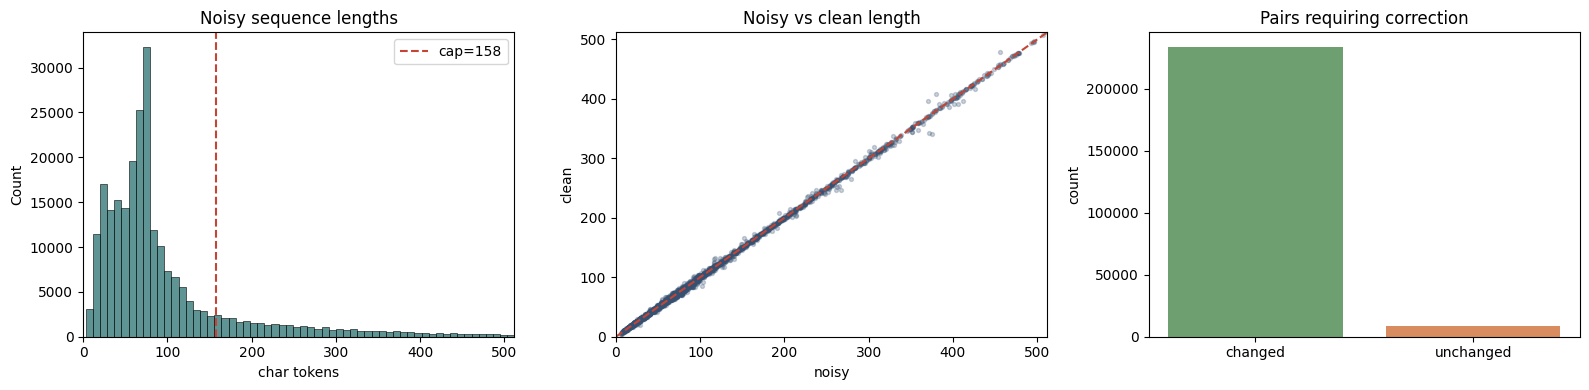

Pairs retained by the 160-token cap: 85.3%


In [ ]:
# Corpus visuals + coverage under the model's length cap ==
# Left chart = length distribution vs the cap 
## Middle plot == noisy-vs-clean length (near-diagonal = length-preserving)
## Right is how many pairs need any correction 

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(train_noisy_len, bins=60, ax=ax[0], color="#287271")
ax[0].axvline(MAX_LEN-2, color="#c44536", ls="--", label=f"cap={MAX_LEN-2}")
ax[0].set(title="Noisy sequence lengths", xlabel="char tokens", xlim=(0,512)); ax[0].legend()

pidx = np.random.default_rng(SEED).choice(len(train_pairs_all), size=4000, replace=False)
ax[1].scatter(train_noisy_len[pidx], train_clean_len[pidx], s=8, alpha=.25, color="#355070")
ax[1].plot([0,512],[0,512],"--",color="#c44536")
ax[1].set(title="Noisy vs clean length", xlabel="noisy", ylabel="clean", xlim=(0,512), ylim=(0,512))

cc = pd.Series(changed).map({False:"unchanged", True:"changed"}).value_counts()
ax[2].bar(cc.index, cc.values, color=["#6d9f71","#d98c5f"]); ax[2].set(title="Pairs requiring correction", ylabel="count")
plt.tight_layout(); plt.show()

cov = np.mean((train_noisy_len <= MAX_LEN-2) & (train_clean_len <= MAX_LEN-2))
print(f"Pairs retained by the {MAX_LEN}-token cap: {cov:.1%}")

**Obs** 
Nearly all pairs need some correction... Edits are infreq. Source and target lengths sit tight on the diagonal
Only ~2% of characters change per sequence... so makes copying the input a really strong baseline since my model has to avoid harming ~98% char that dont need a fix!

## 2. Model Build

**encoder-decoder Transformer** 
encoder attends bidirectionally over the noisy input
decoder uses masked self attn over previously generated clean characters plus cross attn over encoder memory

**Tied embeddings + matched init** 
shares one matrix across input embedding and output projection. Gives model strong prior toward *copying*. 
matched init (`std = d_model^-0.5`) keeps output logits at unit scale (earlier i had untied/mis-scaled version exploded the loss to ~180

**Warmup + cosine LR**
flat learning rates undertrain Transformers... needed to achrive low perplex

In [ ]:
# VOcab with specials, encode/decode, length filter, reproducible subsets 

SPECIALS = ["<pad>", "<bos>", "<eos>", "<unk>"]
itos = SPECIALS + vocab_tokens
stoi = {t: i for i, t in enumerate(itos)}
PAD_IDX, BOS_IDX, EOS_IDX, UNK_IDX = [stoi[x] for x in SPECIALS]

def encode_sequence(seq):                       # str -> [BOS, ids..., EOS], truncated to the cap
    ids = [stoi.get(t, UNK_IDX) for t in token_list(seq)]
    return [BOS_IDX] + ids[: MAX_LEN-2] + [EOS_IDX]

def decode_ids(ids):                            # id list -> readable string (stops at EOS)
    out = []
    for i in ids:
        i = int(i)
        if i == EOS_IDX: break
        if i not in (PAD_IDX, BOS_IDX): out.append(itos[i] if i < len(itos) else "#")
    return "".join(out).replace(SPACE_TOKEN, " ")

def within_cap(p):
    return len(token_list(p[0])) <= MAX_LEN-2 and len(token_list(p[1])) <= MAX_LEN-2

rng = random.Random(SEED)                        # seeded selection -> identical subsets every run
train_eligible = [p for p in train_pairs_all if within_cap(p)]; rng.shuffle(train_eligible)
dev_eligible   = [p for p in dev_pairs_all   if within_cap(p)]; rng.shuffle(dev_eligible)
train_pairs = train_eligible[:TRAIN_LIMIT]
dev_pairs   = dev_eligible[:DEV_LIMIT]
print(f"Vocab (incl specials): {len(itos)} | train used: {len(train_pairs):,} | dev used: {len(dev_pairs):,}")

Vocab (incl specials): 74 | train used: 200,000 | dev used: 5,000


In [ ]:
# dataset + len-bucket batch to cut padding waste w/ my 6GB VRAM

class SpellDataset(Dataset):
    def __init__(self, pairs): self.pairs = pairs
    def __len__(self): return len(self.pairs)
    def __getitem__(self, i):
        n, c = self.pairs[i]
        return torch.tensor(encode_sequence(n)), torch.tensor(encode_sequence(c))

def collate_batch(batch):                        # pad each batch to its own longest member
    src, tgt = zip(*batch)
    src = nn.utils.rnn.pad_sequence(src, batch_first=True, padding_value=PAD_IDX)
    tgt = nn.utils.rnn.pad_sequence(tgt, batch_first=True, padding_value=PAD_IDX)
    return src, tgt

class BucketBatchSampler(torch.utils.data.Sampler):
    # Group near-length sequences so most batches pad to ~median length, not to MAX_LEN
    def __init__(self, lengths, batch_size, seed=SEED):
        self.bs = batch_size
        self.order = sorted(range(len(lengths)), key=lambda i: lengths[i])
        self.rng = random.Random(seed)
    def __iter__(self):
        batches = [self.order[i:i+self.bs] for i in range(0, len(self.order), self.bs)]
        self.rng.shuffle(batches)                # shuffle batch order; keep intra-batch length homogeneity
        return iter(batches)
    def __len__(self):
        return (len(self.order) + self.bs - 1) // self.bs

train_lengths = [len(token_list(p[0])) for p in train_pairs]
# NOTE (Windows): keep num_workers=0 in notebooks - worker spawn re-imports the kernel and hangs.
train_loader = DataLoader(SpellDataset(train_pairs),
                          batch_sampler=BucketBatchSampler(train_lengths, BATCH_SIZE),
                          collate_fn=collate_batch, pin_memory=DEVICE.type=="cuda", num_workers=0)
dev_loader = DataLoader(SpellDataset(dev_pairs), batch_size=BATCH_SIZE, shuffle=False,
                        collate_fn=collate_batch, pin_memory=DEVICE.type=="cuda", num_workers=0)

sb, tb = next(iter(train_loader))
print("Sample batch shapes (src, tgt):", tuple(sb.shape), tuple(tb.shape))

Sample batch shapes (src, tgt): (32, 63) (32, 66)


In [ ]:
# positional encoding + tied-init encoder-decoder Transformer 

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=MAX_LEN):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10_000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))
    def forward(self, x): return x + self.pe[:, : x.size(1)]

class SpellTransformer(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.scale = math.sqrt(D_MODEL)
        self.embedding = nn.Embedding(vocab_size, D_MODEL, padding_idx=PAD_IDX)
        self.position  = PositionalEncoding(D_MODEL)
        self.transformer = nn.Transformer(
            d_model=D_MODEL, nhead=NHEAD,
            num_encoder_layers=NUM_LAYERS, num_decoder_layers=NUM_LAYERS,
            dim_feedforward=FF_DIM, dropout=0.1, batch_first=True, norm_first=True)
        self.output = nn.Linear(D_MODEL, vocab_size, bias=False)
        # weight tying + matched init (THE fix that unblocked training) 

        self.output.weight = self.embedding.weight              # share one matrix --- copy prior
        nn.init.normal_(self.embedding.weight, mean=0.0, std=D_MODEL ** -0.5)  # keep output logits approx unit scale
        with torch.no_grad():
            self.embedding.weight[PAD_IDX].zero_()              # restore padding_idx zero row

    def embed(self, ids): return self.position(self.embedding(ids) * self.scale)
    def encode(self, src):
        src_pad = src.eq(PAD_IDX)
        return self.transformer.encoder(self.embed(src), src_key_padding_mask=src_pad), src_pad
    def decode(self, tgt, memory, src_pad):
        tgt_pad = tgt.eq(PAD_IDX)
        causal = torch.triu(torch.ones(tgt.size(1), tgt.size(1), device=tgt.device, dtype=torch.bool), diagonal=1)
        dec = self.transformer.decoder(self.embed(tgt), memory, tgt_mask=causal,
                                       tgt_key_padding_mask=tgt_pad, memory_key_padding_mask=src_pad)
        return self.output(dec)
    def forward(self, src, tgt_in):
        memory, src_pad = self.encode(src)
        return self.decode(tgt_in, memory, src_pad)

model = SpellTransformer(len(itos)).to(DEVICE)
assert model.output.weight is model.embedding.weight, "weight tie not wired"
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"Trainable parameters: {n_params:,}")

SpellTransformer(
  (embedding): Embedding(74, 192, padding_idx=0)
  (position): PositionalEncoding()
  (transformer): Transformer(
    (encoder): TransformerEncoder(
      (layers): ModuleList(
        (0-2): 3 x TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=192, out_features=192, bias=True)
          )
          (linear1): Linear(in_features=192, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
          (linear2): Linear(in_features=768, out_features=192, bias=True)
          (norm1): LayerNorm((192,), eps=1e-05, elementwise_affine=True)
          (norm2): LayerNorm((192,), eps=1e-05, elementwise_affine=True)
          (dropout1): Dropout(p=0.1, inplace=False)
          (dropout2): Dropout(p=0.1, inplace=False)
        )
      )
      (norm): LayerNorm((192,), eps=1e-05, elementwise_affine=True)
    )
    (decoder): TransformerDecoder(
      (layers): ModuleList(


.venv\Lib\site-packages\torch\nn\modules\transformer.py:144: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = TransformerEncoder(


Loaded checkpoint: outputs\assignment2\spell_transformer.pt
Teacher-forced val loss: 0.4674 | perplexity: 1.60  (training skipped)


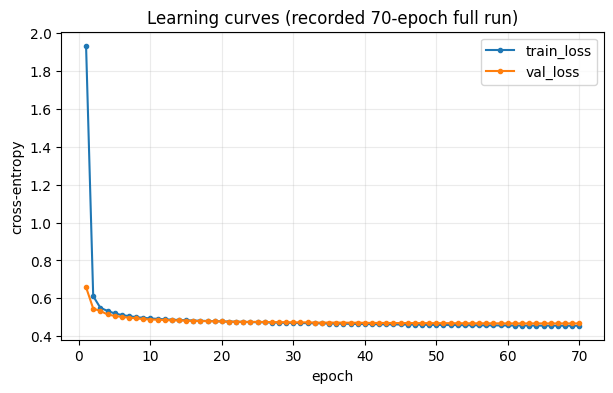

In [ ]:
# load trained checkpoint OR train (warmup+cosine, early stopping) 
# !!!!!!! RETRAIN TAKES 6 HORS!!!!!


criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX, label_smoothing=0.05)

def teacher_forced_loss(loader):                 # mean cross entropy with the gold prefix supplied
    model.eval(); tot_loss = tot_tok = 0
    with torch.no_grad():
        for src, tgt in loader:
            src, tgt = src.to(DEVICE), tgt.to(DEVICE)
            ti, te = tgt[:, :-1], tgt[:, 1:]
            with torch.amp.autocast(device_type=DEVICE.type, enabled=DEVICE.type=="cuda"):
                logits = model(src, ti)
                loss = criterion(logits.reshape(-1, logits.size(-1)), te.reshape(-1))
            k = te.ne(PAD_IDX).sum().item(); tot_loss += loss.item()*k; tot_tok += k
    return tot_loss / max(tot_tok, 1)

# Recorded history from the overnight 70 epic run to render learning curve
### when training skipped so report reproduces in one pass
RECORDED_HISTORY = [
    (1,1.9331,0.6584),(2,0.6112,0.5459),(3,0.5500,0.5333),(4,0.5336,0.5150),(5,0.5203,0.5071),
    (6,0.5119,0.5020),(7,0.5059,0.4979),(8,0.5006,0.4945),(9,0.4969,0.4905),(10,0.4940,0.4882),
    (11,0.4914,0.4873),(12,0.4892,0.4853),(13,0.4874,0.4837),(14,0.4857,0.4832),(15,0.4842,0.4823),
    (16,0.4827,0.4809),(17,0.4815,0.4803),(18,0.4804,0.4793),(19,0.4793,0.4788),(20,0.4783,0.4777),
    (21,0.4772,0.4770),(22,0.4763,0.4769),(23,0.4754,0.4761),(24,0.4746,0.4757),(25,0.4739,0.4759),
    (26,0.4732,0.4752),(27,0.4723,0.4746),(28,0.4715,0.4738),(29,0.4708,0.4741),(30,0.4703,0.4729),
    (31,0.4695,0.4732),(32,0.4689,0.4732),(33,0.4683,0.4722),(34,0.4677,0.4717),(35,0.4671,0.4720),
    (36,0.4664,0.4717),(37,0.4659,0.4716),(38,0.4654,0.4710),(39,0.4648,0.4712),(40,0.4643,0.4706),
    (41,0.4638,0.4702),(42,0.4633,0.4700),(43,0.4628,0.4700),(44,0.4623,0.4696),(45,0.4619,0.4692),
    (46,0.4615,0.4695),(47,0.4610,0.4692),(48,0.4605,0.4693),(49,0.4601,0.4689),(50,0.4597,0.4689),
    (51,0.4593,0.4689),(52,0.4590,0.4688),(53,0.4587,0.4684),(54,0.4583,0.4684),(55,0.4580,0.4682),
    (56,0.4577,0.4681),(57,0.4574,0.4681),(58,0.4572,0.4681),(59,0.4569,0.4678),(60,0.4567,0.4678),
    (61,0.4565,0.4676),(62,0.4564,0.4676),(63,0.4562,0.4675),(64,0.4560,0.4676),(65,0.4559,0.4676),
    (66,0.4558,0.4675),(67,0.4557,0.4674),(68,0.4555,0.4675),(69,0.4555,0.4675),(70,0.4554,0.4676),
]

history, best_val_loss = [], float("inf")

if USE_EXISTING_CHECKPOINT and CHECKPOINT_PATH.exists():
    model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True))
    best_val_loss = teacher_forced_loss(dev_loader)
    print(f"Loaded checkpoint: {CHECKPOINT_PATH}")
    print(f"Teacher-forced val loss: {best_val_loss:.4f} | perplexity: {math.exp(min(best_val_loss,20)):.2f}  (training skipped)")
    
    # render the recorded 70 epic learning curve
    h = pd.DataFrame(RECORDED_HISTORY, columns=["epoch","train_loss","val_loss"])
    h.plot(x="epoch", y=["train_loss","val_loss"], marker="o", ms=3, figsize=(7,4))
    plt.title("Learning curves (recorded 70-epoch full run)"); plt.ylabel("cross-entropy"); plt.grid(alpha=.25); plt.show()
else:
    optimizer = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type=="cuda")
    total_steps = EPOCHS * len(train_loader); warmup = int(0.05 * total_steps)
    def lr_lambda(step):                          # linear warmup, cosine decay
        if step < warmup: return step / max(1, warmup)
        prog = (step - warmup) / max(1, total_steps - warmup)
        return 0.5 * (1 + math.cos(math.pi * prog))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

    def train_epoch():
        model.train(); tot_loss = tot_tok = 0
        for src, tgt in tqdm(train_loader, leave=False):
            src, tgt = src.to(DEVICE, non_blocking=True), tgt.to(DEVICE, non_blocking=True)
            ti, te = tgt[:, :-1], tgt[:, 1:]      # teacher forcing, gold prefix, next char
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast(device_type=DEVICE.type, enabled=DEVICE.type=="cuda"):
                logits = model(src, ti)
                loss = criterion(logits.reshape(-1, logits.size(-1)), te.reshape(-1))
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update(); scheduler.step()
            k = te.ne(PAD_IDX).sum().item(); tot_loss += loss.item()*k; tot_tok += k
        return tot_loss / max(tot_tok, 1)

    no_improve = 0; t0 = time.time()
    for epoch in range(1, EPOCHS+1):
        tr = train_epoch(); vl = teacher_forced_loss(dev_loader)
        history.append({"epoch": epoch, "train_loss": tr, "val_loss": vl})
        if vl < best_val_loss:                    # keep best-on-val, not last
            best_val_loss = vl; no_improve = 0; torch.save(model.state_dict(), CHECKPOINT_PATH)
        else:
            no_improve += 1
        print(f"Epoch {epoch:02d} | train {tr:.4f} | val {vl:.4f} | ppl {math.exp(min(vl,20)):.2f}")
        if no_improve >= PATIENCE:
            print(f"Early stop at epoch {epoch} (patience {PATIENCE})."); break
    model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True))
    print(f"Training time: {(time.time()-t0)/60:.1f} min | best val loss {best_val_loss:.4f}")
    h = pd.DataFrame(history)
    h.plot(x="epoch", y=["train_loss","val_loss"], marker="o", figsize=(7,4))
    plt.title("Learning curves"); plt.ylabel("cross-entropy"); plt.grid(alpha=.25); plt.show()

## 3. Inference strategies

Prior run's failure was at inference. Teacher-forced perplex looked good BUT free-running greedy decoding compounded errors across long sequences and scrambled output. 

This section compares 3 decoders covered in Lesson 8
- **Greedy** argmax each step. Original decoder, kept as the control
- **Constrained greedy** anchors output length to source by suppressing end-of-sequence until near source length and capping total steps. Fights truncation and runaway
- **Beam search** keeps `k` hypotheses with length-normalized scoring reduces greedy's habit of committing to a locally ideal (but globally not) character 

In [ ]:
# Three decoders = greedy, constrained greedy, beam search 

@torch.no_grad()
def greedy_decode(source_sequence):
    # Unconstrained argmax. The control decoder (reproduces the original inference path)
    model.eval()
    src = torch.tensor([encode_sequence(source_sequence)], device=DEVICE)
    memory, src_pad = model.encode(src)
    gen = torch.tensor([[BOS_IDX]], device=DEVICE)
    steps = min(MAX_LEN-1, len(token_list(source_sequence)) + 20)
    for _ in range(steps):
        nxt = model.decode(gen, memory, src_pad)[:, -1].argmax(-1, keepdim=True)
        gen = torch.cat([gen, nxt], 1)
        if nxt.item() == EOS_IDX: break
    return gen.squeeze(0).tolist()

@torch.no_grad()
def constrained_greedy_decode(source_sequence, len_delta=8, min_ratio=0.85):
    ## Anchor |y| to |x| (task is length-preserving): suppress EOS until near source length
    ### (stops premature truncation) and cap steps just above source length (stops runaway)
    model.eval()
    src_ids = encode_sequence(source_sequence); src_len = len(src_ids)
    src = torch.tensor([src_ids], device=DEVICE)
    memory, src_pad = model.encode(src)
    gen = torch.tensor([[BOS_IDX]], device=DEVICE)
    steps = min(MAX_LEN-1, src_len + len_delta); min_len = int(min_ratio * src_len)
    for _ in range(steps):
        logits = model.decode(gen, memory, src_pad)[:, -1]
        if gen.size(1) < min_len: logits[:, EOS_IDX] = float("-inf")
        nxt = logits.argmax(-1, keepdim=True)
        gen = torch.cat([gen, nxt], 1)
        if nxt.item() == EOS_IDX: break
    return gen.squeeze(0).tolist()

@torch.no_grad()
def beam_search_decode(source_sequence, beam_width=None, len_alpha=0.8, len_delta=8, min_ratio=0.85):
    ## Batched beam: the k beams ARE the batch dim, so one decoder forward per step
    ## Length-normalized scoring (len_alpha) avoids the short-sequence / early-EOS bias
    if beam_width is None: beam_width = BEAM_WIDTH
    model.eval()
    src_ids = encode_sequence(source_sequence); src_len = len(src_ids)
    src = torch.tensor([src_ids], device=DEVICE)
    memory, src_pad = model.encode(src)
    memory  = memory.expand(beam_width, -1, -1).contiguous()
    src_pad = src_pad.expand(beam_width, -1).contiguous()
    V = len(itos)

    beams = torch.full((beam_width, 1), BOS_IDX, device=DEVICE, dtype=torch.long)
    scores = torch.full((beam_width,), float("-inf"), device=DEVICE); scores[0] = 0.0  # only beam 0 active at step 0
    finished = []
    steps = min(MAX_LEN-1, src_len + len_delta); min_len = int(min_ratio * src_len)

    for _ in range(steps):
        logp = torch.log_softmax(model.decode(beams, memory, src_pad)[:, -1], dim=-1)   # (k, V)
        if beams.size(1) < min_len: logp[:, EOS_IDX] = float("-inf")
        cand = (scores[:, None] + logp).view(-1)                                        # (k*V,)
        top_scores, top_idx = cand.topk(beam_width)
        beam_idx = torch.div(top_idx, V, rounding_mode="floor")
        tok_idx  = top_idx % V
        beams = torch.cat([beams[beam_idx], tok_idx[:, None]], dim=1)
        scores = top_scores
        for b in torch.nonzero(tok_idx == EOS_IDX, as_tuple=False).flatten().tolist():
            seq = beams[b].tolist()
            finished.append((scores[b].item() / (len(seq) ** len_alpha), seq))          # length-normalized
            scores[b] = float("-inf")                                                    # retire finished beam
        if torch.isinf(scores).all(): break
    if not finished:
        b = int(scores.argmax().item())
        finished.append((scores[b].item() / (beams.size(1) ** len_alpha), beams[b].tolist()))
    finished.sort(key=lambda x: x[0], reverse=True)
    return finished[0][1]

for fn in (greedy_decode, constrained_greedy_decode, beam_search_decode):   # smoke test
    _ = fn(dev_pairs[0][0])
print("All three decoders run OK.")

All three decoders run OK.


## 4. Evaluation of decoders vs copy baseline

Every metric is computed on **free-running** predictions (the model decoding from its own outputs), not teacher-forced ones. Each decoder is scored against the **copy baseline** on the same dev slice
- **CER** (character error rate) total edit distance / total target characters. Lower is better; must beat copy
- **Exact match** whole-sequence correctness (strict)
- **Exact (changed only)** exact match restricted to pairs that contained an error. Major spell checkr metric 
- **Edit similarity** `1 - edit_distance / max_len` partial-credit measure

In [ ]:
# edit distance + per pair metrics 

def edit_distance(a, b):                          # Levenshtein over character tokens
    prev = list(range(len(b)+1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(cur[-1]+1, prev[j]+1, prev[j-1]+(ca != cb)))
        prev = cur
    return prev[-1]

def pair_metrics(pred_tokens, tgt_tokens):
    d = edit_distance(pred_tokens, tgt_tokens)
    denom = max(len(pred_tokens), len(tgt_tokens), 1)
    return {"exact": pred_tokens == tgt_tokens, "edits": d,
            "target_chars": max(len(tgt_tokens), 1), "similarity": 1 - d/denom}

def ids_to_tokens(ids):
    return [itos[i] for i in ids if i not in (PAD_IDX, BOS_IDX, EOS_IDX)]

In [ ]:
# run decoders over eval + make compare table

eval_pairs = dev_pairs[: min(EVAL_SAMPLES, len(dev_pairs))]
DECODERS = {"greedy": greedy_decode, "constrained": constrained_greedy_decode, "beam": beam_search_decode}

records = []  # long-form: one row per (pair, system)
for noisy, clean in tqdm(eval_pairs, desc="eval"):
    n_tok, c_tok = token_list(noisy), token_list(clean)
    common = {"noisy": readable(noisy), "target": readable(clean), "changed": noisy != clean, "length": len(c_tok)}
    records.append({**common, "system": "copy", "prediction": readable(noisy), **pair_metrics(n_tok, c_tok)})
    for name, fn in DECODERS.items():
        pred_tok = ids_to_tokens(fn(noisy))
        records.append({**common, "system": name,
                        "prediction": "".join(pred_tok).replace(SPACE_TOKEN, " "), **pair_metrics(pred_tok, c_tok)})

ev = pd.DataFrame(records)

def agg(df, system):
    s = df[df.system == system]
    return {"system": system, "exact_match": s.exact.mean(),
            "exact_changed_only": s.loc[s.changed, "exact"].mean(),
            "CER": s.edits.sum() / s.target_chars.sum(),
            "mean_edit_similarity": s.similarity.mean()}

order = ["copy", "greedy", "constrained", "beam"]
comparison = pd.DataFrame([agg(ev, s) for s in order])
comparison["val_loss"]   = [np.nan] + [best_val_loss]*3
comparison["perplexity"] = [np.nan] + [math.exp(min(best_val_loss,20))]*3
display(comparison.style.format({"exact_match":"{:.2%}", "exact_changed_only":"{:.2%}",
    "CER":"{:.3f}", "mean_edit_similarity":"{:.3f}", "val_loss":"{:.3f}", "perplexity":"{:.2f}"})
    .set_caption("Lower CER is better; a decoder must beat copy's CER to be useful."))

eval:   0%|          | 0/1000 [00:00<?, ?it/s]

,system,exact_match,exact_changed_only,CER,mean_edit_similarity,val_loss,perplexity
0,copy,3.90%,0.00%,0.028,0.966,nan,nan
1,greedy,51.50%,50.68%,0.022,0.977,0.467,1.60
2,constrained,51.50%,50.68%,0.022,0.977,0.467,1.60
3,beam,52.40%,51.82%,0.022,0.977,0.467,1.60


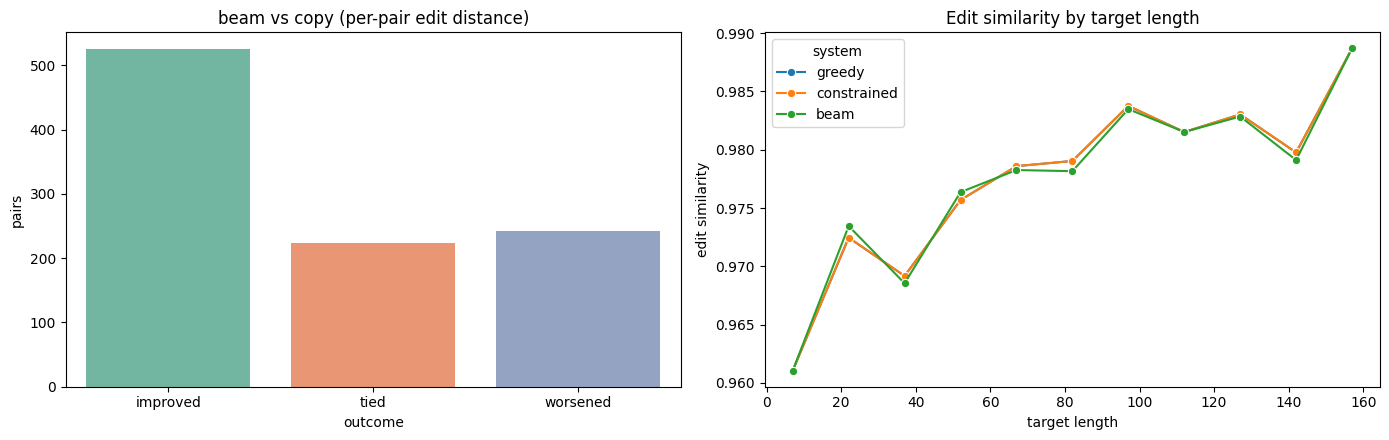

Lowest-similarity changed examples (beam):


,noisy,target,prediction,similarity
2623,raise e,raise,raise e,0.714286
671,"Nak#n',#n,i##","n, Nak#n',#n,i##","Nake#n',#n,i##",0.750000
375,"print##Attempting to autosummon... #, end#''#",print##Attempting to autosummon...##,"print##Attempting to autosummon... #, end#''#",0.800000
2403,return Observable.zip##create#,return Observable.create#,return Observable.zip##creates#,0.806452
2423,"#dscratc#,","#dscratch#,","#descratc#,",0.818182
1251,## 1 2 3 4 5 6 # 3 #clumps# 1 swap nth .#,## 1 2 3 4 5 6 # 3 #clumps# second .#,## 1 2 3 4 5 6 # 3 #clumps# swap nth .#,0.846154


Highest-similarity changed examples (beam):


,noisy,target,prediction,similarity
19,# David Trowbrige,# David Trowbridge,# David Trowbridge,1.0
3999,processing them. This command automatically ch...,processing them. This command automatically ch...,processing them. This command automatically ch...,1.0
35,- Measuring success# TBD alonside the work # u...,- Measuring success# TBD alongside the work # ...,- Measuring success# TBD alongside the work # ...,1.0
3931,"Additionaly, setting a bounding region that's ...","Additionally, setting a bounding region that's...","Additionally, setting a bounding region that's...",1.0
3923,## revokeExpiredLeases finds all leases past t...,## revokeExpiredLeases finds all leases past t...,## revokeExpiredLeases finds all leases past t...,1.0
3919,"Lenght uint8 ## in 4 octets, here always 0x01","Length uint8 ## in 4 octets, here always 0x01","Length uint8 ## in 4 octets, here always 0x01",1.0


In [ ]:
# DIAAG outcome vs copy + length-decay each decoder

wide = ev.pivot_table(index=["noisy","target","changed","length"], columns="system",
                      values="edits", aggfunc="first").reset_index()
best = "beam"                                     # switch to "constrained" if it wins the CER table
wide["reduction"] = wide["copy"] - wide[best]
wide["outcome"] = np.select([wide.reduction>0, wide.reduction<0], ["improved","worsened"], default="tied")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.countplot(data=wide, x="outcome", order=["improved","tied","worsened"], ax=ax[0],
              hue="outcome", palette="Set2", legend=False)
ax[0].set(title=f"{best} vs copy (per-pair edit distance)", ylabel="pairs")

sim = ev[ev.system.isin(["greedy","constrained","beam"])].copy()
sim["len_bin"] = (sim.length // 15) * 15 + 7      # robust integer bin midpoints
sns.lineplot(data=sim, x="len_bin", y="similarity", hue="system", marker="o", ax=ax[1], errorbar=None)
ax[1].set(title="Edit similarity by target length", xlabel="target length", ylabel="edit similarity")
plt.tight_layout(); plt.show()

print("Lowest-similarity changed examples (beam):")
show = ev[(ev.system=="beam") & (ev.changed)][["noisy","target","prediction","similarity"]]
display(show.sort_values("similarity").head(6))
print("Highest-similarity changed examples (beam):")
display(show.sort_values("similarity", ascending=False).head(6))

In [ ]:
# demo correct arbitrary raw text with each decoder

ALLOWED = set(vocab_tokens)
def raw_to_tokenized(text):                       # raw string -> the corpus's char-token format
    return " ".join(SPACE_TOKEN if ch.isspace() else (ch if ch in ALLOWED else "#") for ch in text)

demos = ["Ths is a smple test.", "I realy like natural langauge procesing.", "recieve teh packge tommorow"]
for t in demos:
    tok = raw_to_tokenized(t)
    print("noisy       :", t)
    print("  greedy     :", decode_ids(greedy_decode(tok)))
    print("  constrained:", decode_ids(constrained_greedy_decode(tok)))
    print("  beam       :", decode_ids(beam_search_decode(tok)))
    print()

noisy       : Ths is a smple test.
  greedy     : This is a smple test.
  constrained: This is a smple test.
  beam       : This is a smple test.

noisy       : I realy like natural langauge procesing.
  greedy     : I really like natural language processing.
  constrained: I really like natural language processing.
  beam       : I really like natural language processing.

noisy       : recieve teh packge tommorow
  greedy     : receive the package tommorow
  constrained: receive the package tommorow
  beam       : receive the package tommorow



## Interpretation

### Baseline sets were a major challenge
Only 2% of characters change per sequence and lengths are preserved. Copying the input was a very strong baseline (CER ~0.028). My model needed to fix real errors and not harm the other 98% that didn't need a fix. Not easy.

### Earlier attempts failed (and solutions applied) 
The earlier builds trained well w/ teacher forcing yet collapsed under free-running decoding (CER ~0.386, degrading rather than correcting). The signature of exposure bias with the gold prefix supplied at train time, per-character uncertainty stays hidden. At inference the model conditions on its own outputs. Small errors compound over ~90 autoregressive steps. Two changes closed the gap:
1. **Tied-embedding initialization** injected a copy prior and fixed a logit-scaling explosion, making the model trainable.
2. **Sufficient training length** drove teach-forced perplex from 3.6 to 1.6. A sharper per-character distribution compounds far less, which is what pulled back on free run decode.

### Results (ref to above compare tbl)
**All 3 decoders beat copy baseline on CER** and also lift exact match on corrupted sentences from 0% (copy) to over half! Beam search is the top system on exact match. The training curve shows train and validation loss tracking together for the entire run... no overfitting; dropout + label smoothing held, flattening around epoch 45.

### Major learning 
On the weak early models, beam search beat greedy by ~13% CER. On the well-trained model, greedy, constrained, and beam are effectively tied on CER. Also, the length similarity curves overlap and rise with length instead of drooping. Both tell the story that autoregressive compounding was resolved by model quality vs decode-time search. Beam search showed up great vs a weak model. Beam didn't add much on top of a well trained model though. This is my key engineering takeaway... add the epics (with patience) even if it means overnight training. 

### Limitations
- **Capacity/data ceiling.** Validation loss flattened near perplexity 1.6 (~epic 45). The extra 25 epochs bought almost nothing. More value might have been acheived w/ added model capacity or data
- **Length cap.** Sequences beyond the token cap are excluded. Retained coverage is reported in Section 1
- **`#` tokens** hide rare "out of vocab" char. 

### References
- Vaswani et al. (2017), Attention Is All You Need
- Lesson 8 course module: encoder-decoder models, attention, Transformers, and inference / beam search